In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kushal0418/synthetic-data-for-ess/synthetic_sample_ess.csv


In [2]:
data = pd.read_csv(r"/kaggle/input/datasets/kushal0418/synthetic-data-for-ess/synthetic_sample_ess.csv")

# EDA

## Data Summary

In [3]:
print(data.head(6))

         X1        X2        X3 Cat1 Cat2  target_code      target
0  0.176133  1.727698 -1.319274    A  Yes            0  Category_1
1 -0.485588  0.845374  0.470220    C  Yes            0  Category_1
2 -0.450979 -1.266292 -1.306431    C  Yes            0  Category_1
3 -0.552348 -0.282998 -0.284167    C  Yes            1  Category_2
4  1.654038  0.546707  1.175560    B   No            3  Category_4
5  1.836705  0.042166 -0.018814    A  Yes            3  Category_4


In [4]:
print(data.isna().sum())

X1             0
X2             0
X3             0
Cat1           0
Cat2           0
target_code    0
target         0
dtype: int64


In [5]:
print(data.describe())

                X1           X2           X3  target_code
count  3000.000000  3000.000000  3000.000000  3000.000000
mean      0.029063     0.017779    -0.001767     1.664667
std       0.997775     0.991050     1.001120     1.197231
min      -3.304530    -4.208254    -3.652985     0.000000
25%      -0.646916    -0.633458    -0.674326     0.750000
50%       0.031059     0.006266    -0.021642     2.000000
75%       0.693369     0.658291     0.678209     3.000000
max       3.637478     3.242520     3.274138     3.000000


## Correlations & Associations

### Correlations within the neumerical attributes only

In [6]:
corr_matrix = data[["X1","X2","X3"]].corr(numeric_only=True)

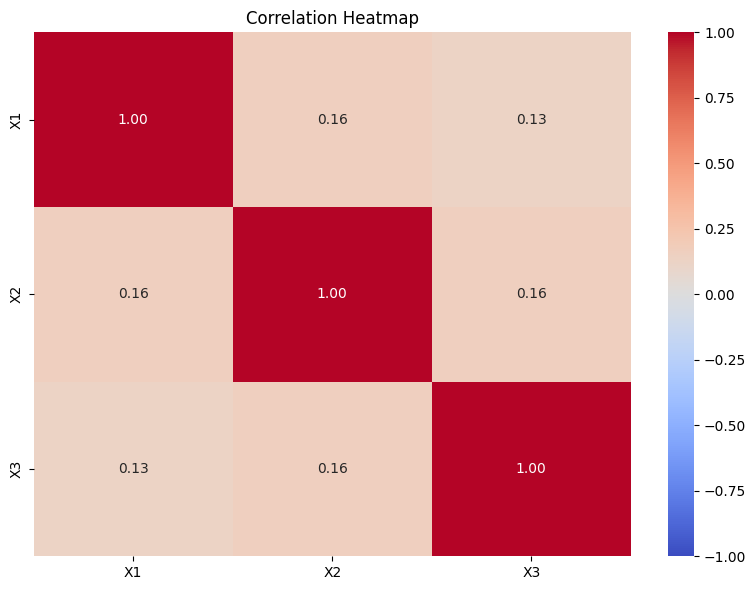

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,        # Show correlation numbers inside cells
    fmt=".2f",         # Round numbers to 2 decimal places
    cmap="coolwarm",   # Diverging color palette (red = positive, blue = negative)
    vmin=-1, vmax=1,   # Anchor color scale from -1 to 1
    center=0           # Center neutral color at 0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

<Axes: >

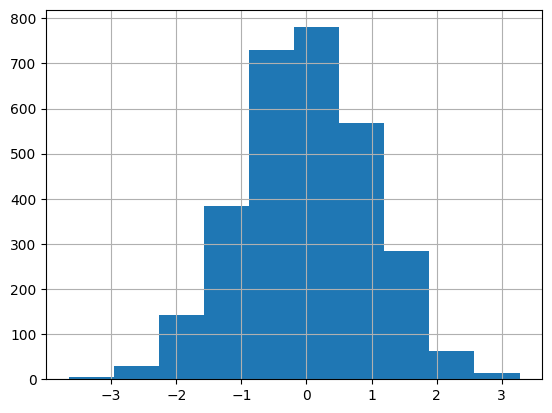

In [8]:
data["X3"].hist()

### Correlations Across All the Attributes

#### Treating the Neumerical Attributes in a Nominal Scale

In [9]:
data["X1_cat"] = np.where(data["X1"]<=-1,"<= -1", 
                         np.where(data["X1"]<= 1, "-1 - 1", " > 1")) 

In [10]:
data["X2_cat"] = np.where(data["X2"]<=-1,"<= -1", 
                         np.where(data["X2"]<= 1, "-1 - 1", " > 1")) 

In [11]:
data["X3_cat"] = np.where(data["X3"]<=-1,"<= -1", 
                         np.where(data["X3"]<= 1, "-1 - 1", " > 1")) 

In [12]:
print(data.columns)

Index(['X1', 'X2', 'X3', 'Cat1', 'Cat2', 'target_code', 'target', 'X1_cat',
       'X2_cat', 'X3_cat'],
      dtype='object')


In [13]:
print(data.head())

         X1        X2        X3 Cat1 Cat2  target_code      target  X1_cat  \
0  0.176133  1.727698 -1.319274    A  Yes            0  Category_1  -1 - 1   
1 -0.485588  0.845374  0.470220    C  Yes            0  Category_1  -1 - 1   
2 -0.450979 -1.266292 -1.306431    C  Yes            0  Category_1  -1 - 1   
3 -0.552348 -0.282998 -0.284167    C  Yes            1  Category_2  -1 - 1   
4  1.654038  0.546707  1.175560    B   No            3  Category_4     > 1   

   X2_cat  X3_cat  
0     > 1   <= -1  
1  -1 - 1  -1 - 1  
2   <= -1   <= -1  
3  -1 - 1  -1 - 1  
4  -1 - 1     > 1  


In [14]:
print(data['Cat1'].value_counts(normalize = True)*100)
print(data['Cat2'].value_counts(normalize = True)*100)
print(data['target'].value_counts(normalize = True)*100)

Cat1
B    34.2
A    33.5
C    32.3
Name: proportion, dtype: float64
Cat2
No     50.9
Yes    49.1
Name: proportion, dtype: float64
target
Category_4    35.500000
Category_1    25.000000
Category_3    20.466667
Category_2    19.033333
Name: proportion, dtype: float64


In [15]:
from scipy.stats import chi2_contingency
from itertools import combinations

# List all your categorical columns
cat_cols = ['target', 'Cat1', 'Cat2', 'X1_cat', 'X2_cat', 'X3_cat']

results = []

# Generate every unique pair of 2 columns
for col1, col2 in combinations(cat_cols, 2):
    # Create the 2D contingency table
    contingency_table = pd.crosstab(data[col1], data[col2])
    
    # Run the Chi-Square test
    chi2_stat, p_val, dof, expected_freq = chi2_contingency(contingency_table)
    
    # Store the results
    results.append({
        'Column 1': col1,
        'Column 2': col2,
        'Chi2 Stat': chi2_stat,
        'P-Value': p_val,
        'DOF': dof
    })

# Convert results into a clean DataFrame
results_df = pd.DataFrame(results)
print(results_df)

   Column 1 Column 2   Chi2 Stat        P-Value  DOF
0    target     Cat1  250.387108   3.390018e-51    6
1    target     Cat2   54.075467   1.081238e-11    3
2    target   X1_cat  533.777125  4.432558e-112    6
3    target   X2_cat  168.281859   1.040795e-33    6
4    target   X3_cat  333.068493   6.641840e-69    6
5      Cat1     Cat2    3.877883   1.438561e-01    2
6      Cat1   X1_cat    2.788128   5.938838e-01    4
7      Cat1   X2_cat    1.080446   8.973622e-01    4
8      Cat1   X3_cat    2.065803   7.236573e-01    4
9      Cat2   X1_cat    1.501011   4.721278e-01    2
10     Cat2   X2_cat    4.177923   1.238157e-01    2
11     Cat2   X3_cat    0.459979   7.945421e-01    2
12   X1_cat   X2_cat   43.515319   8.089025e-09    4
13   X1_cat   X3_cat   23.676250   9.274048e-05    4
14   X2_cat   X3_cat   31.933900   1.973538e-06    4


#### Treating the Numerical Attributes in the Ordinal Scale

In [16]:
from scipy.stats import kendalltau, spearmanr

map1 = {'<= -1': 1, '-1 - 1': 2, '> 1': 3}

data['X1_cat_map'] = data['X1_cat'].map(map1)
data['X2_cat_map'] = data['X2_cat'].map(map1)
data['X3_cat_map'] = data['X3_cat'].map(map1)
data['target_code_map'] = data['target_code'] + 1

cols = ['X1_cat_map', 'X2_cat_map', 'X3_cat_map','target_code_map']
sub_df = data[cols]
print(data.head())
# Option A: Loop over all 6 unique pairs among the 4 variables
pair_results = []
for col1, col2 in combinations(cols, 2):
  stat, p_val = kendalltau(sub_df[col1], sub_df[col2], nan_policy="omit")
  pair_results.append(
      {"var1": col1, "var2": col2, "tau": stat, "p_value": p_val}
  )

results_df = pd.DataFrame(pair_results)
print(results_df)


         X1        X2        X3 Cat1 Cat2  target_code      target  X1_cat  \
0  0.176133  1.727698 -1.319274    A  Yes            0  Category_1  -1 - 1   
1 -0.485588  0.845374  0.470220    C  Yes            0  Category_1  -1 - 1   
2 -0.450979 -1.266292 -1.306431    C  Yes            0  Category_1  -1 - 1   
3 -0.552348 -0.282998 -0.284167    C  Yes            1  Category_2  -1 - 1   
4  1.654038  0.546707  1.175560    B   No            3  Category_4     > 1   

   X2_cat  X3_cat  X1_cat_map  X2_cat_map  X3_cat_map  target_code_map  
0     > 1   <= -1         2.0         NaN         1.0                1  
1  -1 - 1  -1 - 1         2.0         2.0         2.0                1  
2   <= -1   <= -1         2.0         1.0         1.0                1  
3  -1 - 1  -1 - 1         2.0         2.0         2.0                2  
4  -1 - 1     > 1         NaN         2.0         NaN                4  
         var1             var2       tau       p_value
0  X1_cat_map       X2_cat_map  0.0871

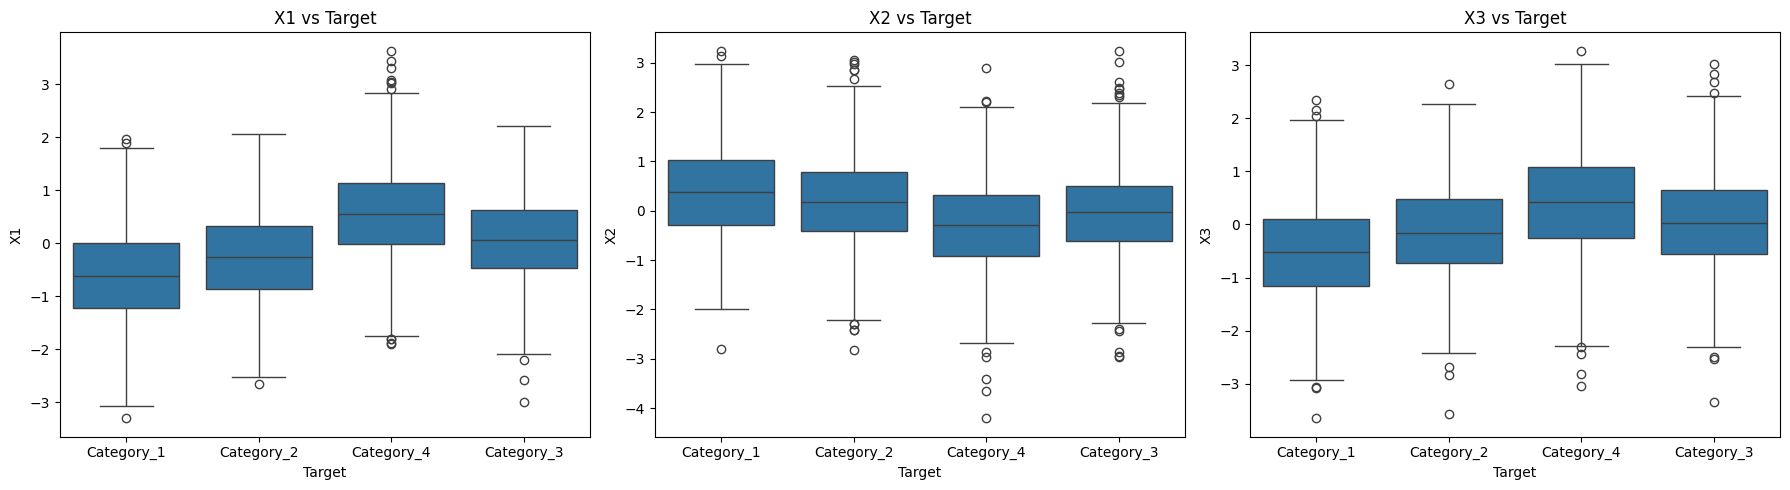

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['X1', 'X2', 'X3']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cols):
    sns.boxplot(
        data=data,
        x='target',
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} vs Target')
    axes[i].set_xlabel('Target')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()